# Latent structure detection: how many groups, if any, does the pR² matrix support?

Leiden assumes *assortative* community structure (dense within a group,
sparse between groups) and found essentially nothing. The GC-hub finding
suggests the real structure might instead be closer to core-periphery (a
few broadly-connected hub cells). Rather than pick one structural
assumption over the other, this notebook uses a method agnostic to the
*shape* of the structure:

1. **Spectral embedding** of the symmetrised coupling matrix (eigenvectors
   of the graph Laplacian) — this embeds cells by the overall pattern of who
   they couple with, and can represent assortative communities,
   core-periphery, or no structure at all, without assuming which.
2. **Gaussian Mixture Model with BIC-based model selection**, sweeping
   `K = 1 ... K_max`. **K=1 is a first-class candidate outcome** — it means
   "no evidence for more than one group," i.e. a single homogeneous
   population. This directly answers "0, 1, 2, or many groups" without
   presupposing the answer is >1.
3. **Permutation null**: the same pipeline is re-run on many edge-shuffled
   versions of the matrix (values randomly reassigned to pairs, marginal
   weight distribution preserved) to check whether any K>1 result found on
   the real data is actually better-supported than what pure noise would
   produce under an identical model-selection procedure — noisy data can
   spuriously "prefer" K>1 under BIC alone, so this is a necessary control,
   not an optional extra.

Run on the same three sessions as before, for both raw and Δ pR² matrices.

In [1]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
import warnings
warnings.filterwarnings('ignore')

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams['font.family'] = 'Arial'

DATA_PATH = '/Users/harryclark/Documents/spatial-manifolds/data/eddie/xgboost_pairwise/'
CC_PATH   = '/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications.csv'
FIG_PATH  = '/Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/latent_structure/'
os.makedirs(FIG_PATH, exist_ok=True)

HISTORY_LENGTH = 100
SESSIONS = [
    dict(mouse=26, day=19, sessions=['VR', 'OF1']),
    dict(mouse=25, day=25, sessions=['OF1']),
    dict(mouse=21, day=26, sessions=['OF1']),
]
RICH_BASELINE = {'VR': 'pos_speed_lfp', 'OF1': 'pos_speed_hd_hing_lfp'}
RAW_BASELINE  = 'null'

K_MAX     = 8
N_EMBED   = K_MAX  # spectral dimensions kept -- deliberately NOT >> K_MAX: extra
                   # noise dimensions let the GMM carve out spurious clusters even
                   # on shuffled data (verified: raw BIC-argmin hit the K ceiling
                   # on 100% of null shuffles at N_EMBED=15 -- see gap-correction below)
N_NULL    = 200
RNG_SEED  = 42

GROUP_COLORS = {
    'Module 0 (GC)':    '#c0392b',
    'Module 1 (GC)':    '#2980b9',
    'GC (unassigned)':  '#8e44ad',
    'Non-grid spatial': '#27ae60',
    'Other':            '#7f8c8d',
}
GROUP_ORDER = list(GROUP_COLORS.keys())

## 1. Load ground truth + pairwise results, build matrices (same construction as before)

In [2]:
cc = pd.read_csv(CC_PATH, low_memory=False)
cc['mouse']      = cc['mouse'].astype(int)
cc['day']        = cc['day'].astype(int)
cc['cluster_id'] = cc['cluster_id'].astype(int)


def get_module_labels(mouse, day):
    sub = cc[(cc.mouse == mouse) & (cc.day == day)].drop_duplicates('cluster_id')
    out = {}
    for _, r in sub.iterrows():
        mod = int(r['grid_module']) if pd.notna(r['grid_module']) else -1
        out[int(r['cluster_id'])] = dict(cell_type=r['cell_type'], module=mod)
    return out


def cell_group(cid, mod_labels):
    info = mod_labels.get(cid, dict(cell_type='Other', module=-1))
    if info['cell_type'] == 'GC' and info['module'] == 0:
        return 'Module 0 (GC)'
    if info['cell_type'] == 'GC' and info['module'] == 1:
        return 'Module 1 (GC)'
    if info['cell_type'] == 'GC':
        return 'GC (unassigned)'
    if info['cell_type'] == 'NG':
        return 'Non-grid spatial'
    return 'Other'


def load_pairwise(mouse, day, session_type):
    pattern = os.path.join(DATA_PATH, f'xgboost_pairwise_M{mouse}_D{day}_h{HISTORY_LENGTH}_{session_type}_*.csv')
    files = sorted(glob.glob(pattern))
    if not files:
        return None
    return pd.concat([pd.read_csv(f, keep_default_na=False) for f in files], ignore_index=True)


def build_pr2_matrix(pw_df, baseline):
    bl = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id == -1)]
          [['target_cluster_id', 'pR2_cv']].rename(columns={'pR2_cv': 'pR2_baseline'})
          .drop_duplicates('target_cluster_id'))
    cv = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id >= 0)]
          [['target_cluster_id', 'covariate_cluster_id', 'pR2_cv']].copy())
    merged = cv.merge(bl, on='target_cluster_id', how='inner')
    merged['d'] = merged['pR2_cv'] - merged['pR2_baseline']
    all_ids = sorted(set(merged.target_cluster_id) | set(merged.covariate_cluster_id))
    idx = {cid: i for i, cid in enumerate(all_ids)}
    N = len(all_ids)
    mat = np.full((N, N), np.nan)
    for row in merged.itertuples(index=False):
        mat[idx[int(row.covariate_cluster_id)], idx[int(row.target_cluster_id)]] = row.d
    np.fill_diagonal(mat, 0)
    sym = np.nan_to_num(np.nanmean(np.stack([mat, mat.T]), axis=0), nan=0.0)
    return sym, all_ids


def build_session_matrices(pw_df, session_type):
    rich = RICH_BASELINE[session_type]
    raw_sym, ids_raw = build_pr2_matrix(pw_df, RAW_BASELINE)
    delta_sym, ids_delta = build_pr2_matrix(pw_df, rich)
    assert ids_raw == ids_delta
    return dict(raw=raw_sym, delta=delta_sym), ids_raw

## 2. Spectral embedding + null-corrected model selection

Plain BIC-argmin does not work here: on a first pass (`N_EMBED=15`), the
shuffled/null matrices "preferred" K>1 in **100% of 200 shuffles**, almost
always pinned at the K ceiling — pure noise, no real pairwise structure at
all, and BIC still wanted more clusters. That happens because a GMM in a
high-dimensional embedding always fits training data better with more
components, and most of those 15 spectral dimensions carry no real signal
in a sample this size (100-280 cells) — BIC's penalty wasn't steep enough
to stop it before hitting the ceiling, on real data *or* noise alike.

Two fixes, both necessary:

1. **Shrink the embedding** to `N_EMBED = K_MAX` — don't hand the model more
   directions than the largest number of groups being considered.
2. **Null-corrected ("gap statistic") K selection**: compute the BIC curve
   on the real matrix AND on `N_NULL` edge-shuffled matrices (values
   randomly reassigned to pairs, no real structure). Because the raw
   "more-clusters-fits-better" trend is present in *both* real and null
   curves, `gap(K) = mean(null_BIC(K)) - real_BIC(K)` cancels that shared
   trend and isolates any advantage attributable to actual data structure.
   `K* = argmax(gap)` — this can and should land on K=1 when there's no
   real advantage anywhere. Final significance: compare the real BIC at
   K* against the null BIC distribution at that same K.

In [3]:
def spectral_embed(sym_mat, n_embed=N_EMBED, eps=1e-8):
    affinity = np.clip(sym_mat, 0, None)
    np.fill_diagonal(affinity, 0)
    deg = affinity.sum(axis=1)
    deg_safe = np.where(deg > eps, deg, eps)
    d_inv_sqrt = 1.0 / np.sqrt(deg_safe)
    L_norm = np.eye(len(sym_mat)) - (d_inv_sqrt[:, None] * affinity * d_inv_sqrt[None, :])
    eigvals, eigvecs = np.linalg.eigh(L_norm)  # ascending eigenvalues
    k = min(n_embed, len(sym_mat) - 1)
    return eigvecs[:, 1:k + 1]  # drop the trivial (near-zero eigenvalue) component


def bic_curve(emb, k_max, seed, n_init=5):
    bics = np.empty(k_max)
    for k in range(1, k_max + 1):
        gm = GaussianMixture(n_components=k, covariance_type='diag', n_init=n_init,
                             random_state=seed, reg_covar=1e-6)
        gm.fit(emb)
        bics[k - 1] = gm.bic(emb)
    return bics


def shuffle_null_bics(sym_mat, n_perm=N_NULL, k_max=K_MAX, n_embed=N_EMBED, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    n = sym_mat.shape[0]
    iu = np.triu_indices(n, k=1)
    vals = sym_mat[iu]
    null_bics = np.empty((n_perm, k_max))
    for p in range(n_perm):
        shuffled = rng.permutation(vals)
        mat = np.zeros((n, n))
        mat[iu] = shuffled
        mat = mat + mat.T
        emb = spectral_embed(mat, n_embed=n_embed)
        null_bics[p] = bic_curve(emb, k_max, seed=seed + p, n_init=2)
    return null_bics


def fit_latent_groups(sym_mat, null_bics, k_max=K_MAX, n_embed=N_EMBED, seed=RNG_SEED):
    emb = spectral_embed(sym_mat, n_embed=n_embed)
    real_bics = bic_curve(emb, k_max, seed=seed, n_init=5)

    gap = null_bics.mean(axis=0) - real_bics       # higher = real beats typical null more, at this K
    best_k = int(np.argmax(gap)) + 1

    gm = GaussianMixture(n_components=best_k, covariance_type='diag', n_init=10,
                         random_state=seed, reg_covar=1e-6)
    gm.fit(emb)
    labels = gm.predict(emb)

    if best_k > 1:
        null_bic_at_k = null_bics[:, best_k - 1]
        p_beats_null = (np.sum(null_bic_at_k <= real_bics[best_k - 1]) + 1) / (len(null_bic_at_k) + 1)
    else:
        p_beats_null = np.nan

    return dict(best_k=best_k, labels=labels, bics=real_bics, gap=gap,
               embedding=emb, p_beats_null=p_beats_null)

## 3. Run across sessions (raw and Δ pR²)

In [4]:
latent_results = {}

for cfg in SESSIONS:
    mouse, day = cfg['mouse'], cfg['day']
    mod_labels = get_module_labels(mouse, day)

    for session_type in cfg['sessions']:
        pw = load_pairwise(mouse, day, session_type)
        if pw is None:
            continue
        mats, cell_ids = build_session_matrices(pw, session_type)
        print(f'\n===== M{mouse} D{day} {session_type} (n={len(cell_ids)}) =====')

        for metric in ('raw', 'delta'):
            sym = mats[metric]
            k_max_eff = min(K_MAX, max(len(cell_ids) // 4, 1))
            null_bics = shuffle_null_bics(sym, n_perm=N_NULL, k_max=k_max_eff)
            null_best_k = np.argmin(null_bics, axis=1) + 1
            res = fit_latent_groups(sym, null_bics, k_max=k_max_eff)

            print(f'  [{metric}] gap-selected K = {res["best_k"]}  '
                  f'(null best-K>1 in {100*np.mean(null_best_k > 1):.0f}% of shuffles; '
                  f'p(real beats null at K={res["best_k"]})={res["p_beats_null"]})')

            latent_results[(mouse, day, session_type, metric)] = dict(
                cell_ids=cell_ids, mod_labels=mod_labels, sym=sym,
                res=res, null_bics=null_bics, p_beats_null=res['p_beats_null'],
            )


===== M26 D19 VR (n=280) =====


  [raw] gap-selected K = 8  (null best-K>1 in 100% of shuffles; p(real beats null at K=8)=0.004975124378109453)


  [delta] gap-selected K = 2  (null best-K>1 in 100% of shuffles; p(real beats null at K=2)=0.5223880597014925)



===== M26 D19 OF1 (n=280) =====


  [raw] gap-selected K = 8  (null best-K>1 in 100% of shuffles; p(real beats null at K=8)=0.004975124378109453)


...

  [raw] gap-selected K = 7  (null best-K>1 in 100% of shuffles; p(real beats null at K=7)=0.004975124378109453)


  [delta] gap-selected K = 6  (null best-K>1 in 100% of shuffles; p(real beats null at K=6)=0.04477611940298507)



===== M21 D26 OF1 (n=147) =====


  [raw] gap-selected K = 5  (null best-K>1 in 100% of shuffles; p(real beats null at K=5)=0.004975124378109453)


  [delta] gap-selected K = 7  (null best-K>1 in 100% of shuffles; p(real beats null at K=7)=0.30845771144278605)


## 4. Visualise: BIC curve vs null, spectral embedding, and matrix reordered by discovered groups

For each example session: **left** — observed BIC vs K (lower is better)
against the null distribution (shaded = 5th-95th percentile band across
shuffles) — if the observed curve doesn't dip meaningfully below the null
band, K=1 (no structure) is the honest read regardless of where the raw
minimum happens to land. **middle** — first two spectral dimensions,
coloured by discovered group. **right** — the Δ pR² matrix reordered by the
*discovered* grouping (not the known module labels) — this is the matrix
sorted however the data itself says cells sort, no ground truth involved.

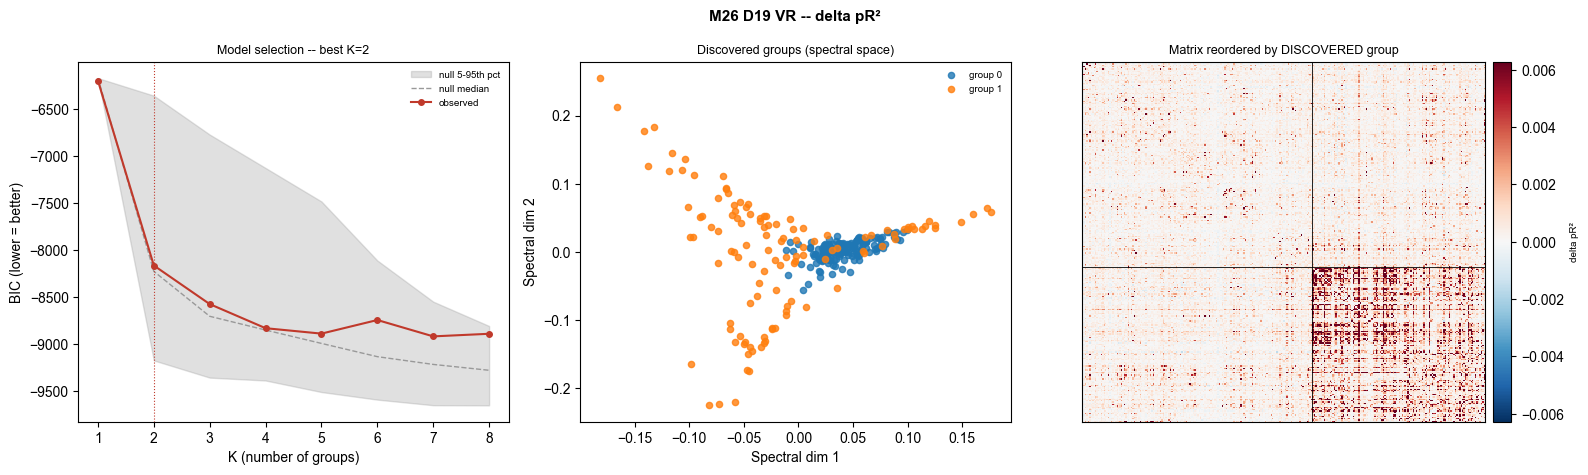

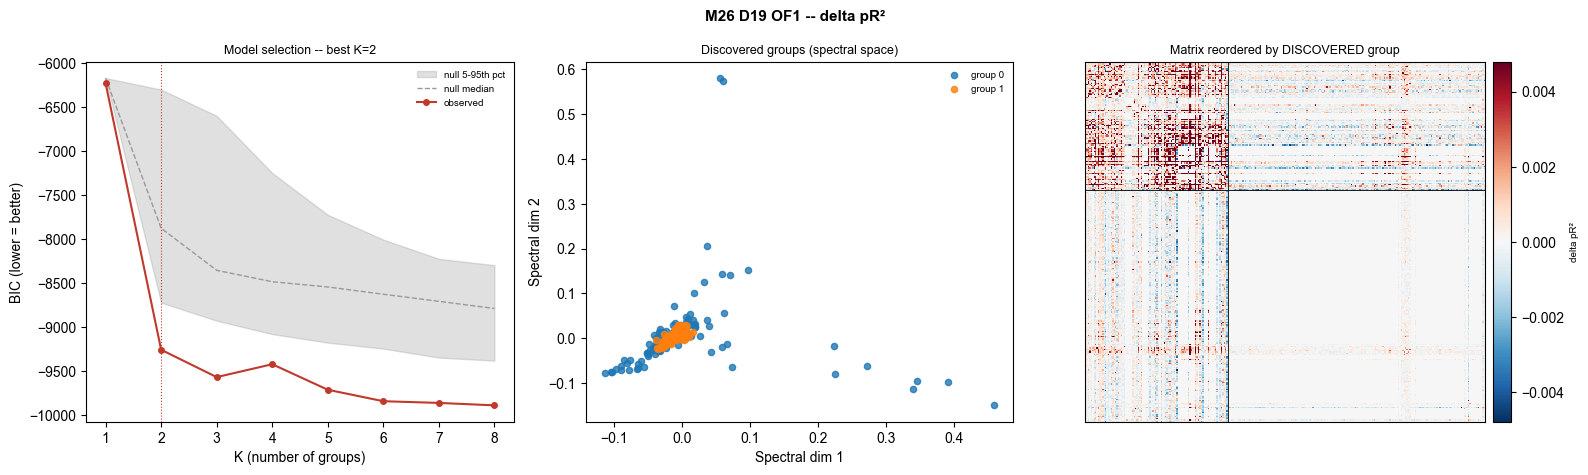

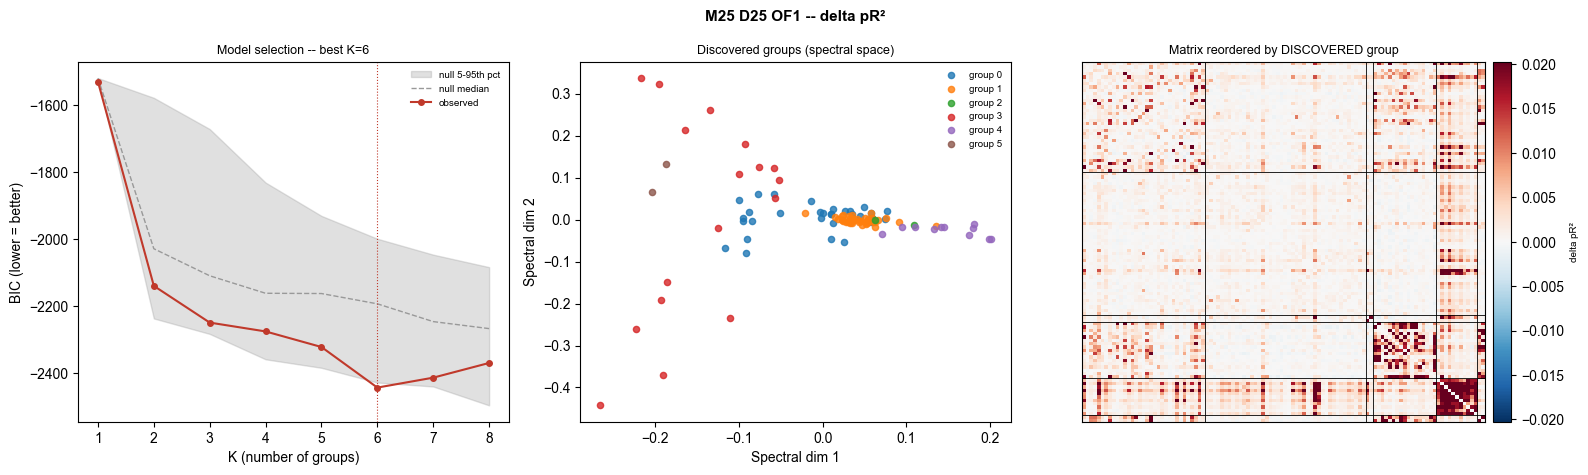

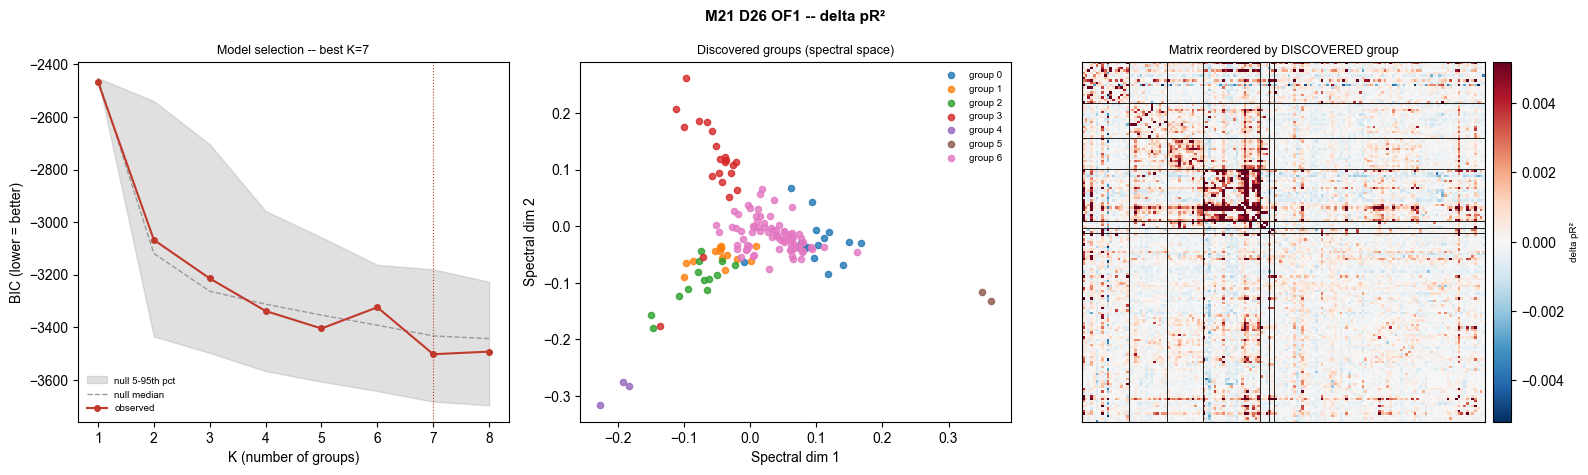

In [5]:
def plot_latent(mouse, day, session_type, metric):
    d = latent_results.get((mouse, day, session_type, metric))
    if d is None:
        print('no result'); return None
    res, null_bics, cell_ids = d['res'], d['null_bics'], d['cell_ids']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

    ax = axes[0]
    ks = np.arange(1, len(res['bics']) + 1)
    lo, hi = np.percentile(null_bics, [5, 95], axis=0)
    ax.fill_between(ks, lo, hi, color='#999999', alpha=0.3, label='null 5-95th pct', linewidth=0, edgecolor='none')
    ax.plot(ks, np.median(null_bics, axis=0), color='#999999', lw=1, ls='--', label='null median')
    ax.plot(ks, res['bics'], color='#c0392b', lw=1.5, marker='o', ms=4, label='observed')
    ax.axvline(res['best_k'], color='#c0392b', lw=0.8, ls=':')
    ax.set_xlabel('K (number of groups)'); ax.set_ylabel('BIC (lower = better)')
    ax.set_title(f'Model selection -- best K={res["best_k"]}', fontsize=9)
    ax.legend(fontsize=7, frameon=False)

    ax = axes[1]
    emb, labels = res['embedding'], res['labels']
    for lab in sorted(set(labels)):
        m = labels == lab
        ax.scatter(emb[m, 0], emb[m, 1], s=20, alpha=0.8, label=f'group {lab}')
    ax.set_xlabel('Spectral dim 1'); ax.set_ylabel('Spectral dim 2')
    ax.set_title('Discovered groups (spectral space)', fontsize=9)
    ax.legend(fontsize=7, frameon=False)

    ax = axes[2]
    order = np.argsort(labels)
    m = d['sym'][np.ix_(order, order)]
    vmax = np.nanpercentile(np.abs(m), 98) if np.any(m != 0) else 1.0
    im = ax.imshow(m, cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest', aspect='auto')
    plt.colorbar(im, ax=ax, fraction=0.045, pad=0.02).set_label(f'{metric} pR²', fontsize=7)
    bounds = np.where(np.diff(labels[order]) != 0)[0] + 0.5
    for b in bounds:
        ax.axhline(b, color='k', lw=0.6); ax.axvline(b, color='k', lw=0.6)
    ax.set_title('Matrix reordered by DISCOVERED group', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle(f'M{mouse} D{day} {session_type} -- {metric} pR²', fontsize=11, fontweight='bold')
    plt.tight_layout()
    return fig


for mouse, day, session_type, metric in [(26, 19, 'VR', 'delta'), (26, 19, 'OF1', 'delta'),
                                         (25, 25, 'OF1', 'delta'), (21, 26, 'OF1', 'delta')]:
    fig = plot_latent(mouse, day, session_type, metric)
    if fig is not None:
        fig.savefig(os.path.join(FIG_PATH, f'latent_M{mouse}D{day}_{session_type}_{metric}.pdf'),
                   dpi=200, bbox_inches='tight')
        plt.show()

## 5. Summary

In [6]:
rows = []
for (mouse, day, session_type, metric), d in latent_results.items():
    rows.append(dict(mouse=mouse, day=day, session_type=session_type, metric=metric,
                     best_k=d['res']['best_k'], p_beats_null=d['p_beats_null']))
summary = pd.DataFrame(rows).sort_values(['mouse', 'day', 'session_type', 'metric'])
summary.to_csv(os.path.join(FIG_PATH, 'latent_structure_summary.csv'), index=False)
summary

,mouse,day,session_type,metric,best_k,p_beats_null
7,21,26,OF1,delta,7,0.308458
6,21,26,OF1,raw,5,0.004975
5,25,25,OF1,delta,6,0.044776
4,25,25,OF1,raw,7,0.004975
3,26,19,OF1,delta,2,0.004975
2,26,19,OF1,raw,8,0.004975
1,26,19,VR,delta,2,0.522388
0,26,19,VR,raw,8,0.004975
